In [1]:
   import sys
   print(sys.version)

3.12.13 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:01) [Clang 20.1.8 ]


In [2]:
!pip install gensim sentence-transformers faiss-cpu

  Using cached gensim-4.4.0.tar.gz (23.3 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached faiss_cpu-1.15.0-cp310-abi3-macosx_14_0_arm64.whl.metadata (7.8 kB)
  Using cached smart_open-8.0.1-py3-none-any.whl.metadata (24 kB)
Using cached faiss_cpu-1.15.0-cp310-abi3-macosx_14_0_arm64.whl (4.9 MB)
Using cached smart_open-8.0.1-py3-none-any.whl (73 kB)
  error: subprocess-exited-with-error
  
  × Building wheel for gensim (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [784 lines of output]
      /private/var/folders/vh/ct099spj1gx7k1z__sx2wtkc0000gn/T/pip-build-env-u16x4e16/overlay/lib/python3.14/site-packages/setuptools/_distutils/dist.py:318: UserWarning: Unknown distribution option: 'test_suite'
        warnings.warn(msg)
      /private/var/folders/vh/ct099spj1gx7k1z__sx2wtkc0000gn/T/pip-build-env-u16x4e16/overlay/lib/python3.14/site-packages/setuptools/_distutils/

In [3]:
!pip install matplotlib

In [7]:
import gensim.downloader as api
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

print("Downloading Word2Vec model")
word_vectors = api.load("word2vec-google-news-300")
print("Downloaded succesfully")

Downloaded succesfully


In [3]:
context_words = ["space", "rocket", "robot", "star"]
predicted = word_vectors.most_similar(positive=context_words, topn=3)

print(f"Context words = {context_words}")
print("Top 3 predictions:")
for word, score in predicted:
    print(f"{word}: {score:.3f}")

Context words = ['space', 'rocket', 'robot', 'star']
Top 3 predictions:
spaceship: 0.625
Shuttle_docks: 0.611
Virgin_Galactic_unveils: 0.596


In [4]:
result = word_vectors.most_similar(positive=['king', 'woman'], negative=['man'], topn=3)
print("Results for King - Man + Woman")
for word, score in result:
    print(f"{word}: {score:.3f}")

Results for King - Man + Woman
queen: 0.712
monarch: 0.619
princess: 0.590


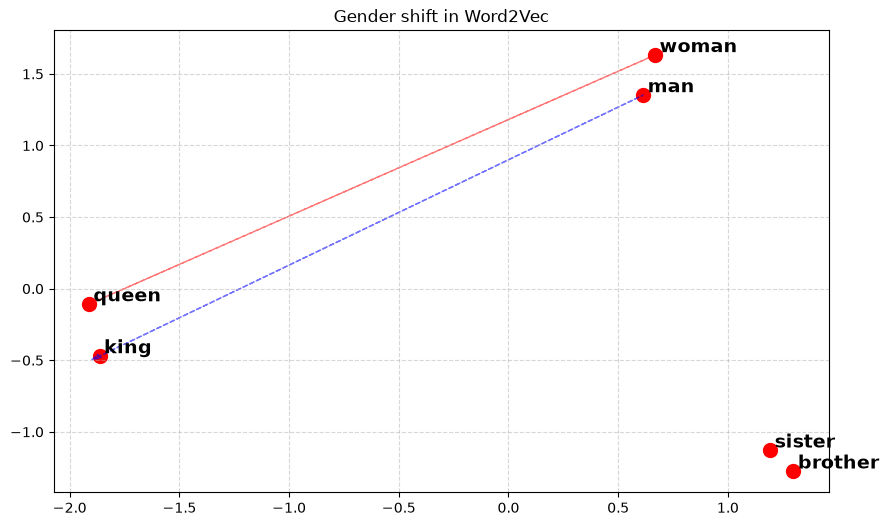

In [5]:
words_to_plot = ['king', 'man', 'queen', 'woman', 'brother', 'sister']
vectors = np.array([word_vectors[w] for w in words_to_plot])

pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

plt.figure(figsize=(10, 6))
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], color='red', s=100)

for i, word in enumerate(words_to_plot):
    plt.annotate(word, (vectors_2d[i, 0]+0.02, vectors_2d[i, 1]+0.02), fontsize=14, weight='bold')

plt.arrow(vectors_2d[1,0], vectors_2d[1,1], vectors_2d[0,0]-vectors_2d[1,0], vectors_2d[0,1]-vectors_2d[1,1], head_width=0.03, color='blue', alpha=0.5, linestyle='--')
plt.arrow(vectors_2d[2,0], vectors_2d[2,1], vectors_2d[3,0]-vectors_2d[2,0], vectors_2d[3,1]-vectors_2d[2,1], head_width=0.03, color='red', alpha=0.5, linestyle='--')

plt.title("Gender shift in Word2Vec")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [2]:
from sentence_transformers import SentenceTransformer, util
print("Loading SentenceTransfomer...")
model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
print("Model is successfully loaded")

Loading SentenceTransfomer...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model is successfully loaded


In [7]:
phrases = [
    "я люблю спелые яблоки",
    "I love ripe apples",
    "как починить кухонный стол"
]

embeddings = model.encode(phrases)

sim_ru_en = util.cos_sim(embeddings[0], embeddings[1])[0][0]
sim_ru_table = util.cos_sim(embeddings[0], embeddings[2])[0][0]

print(f"Сходство между 'я люблю спелые яблоки' и 'I love ripe apples': {sim_ru_en:.3f} (Смысл совпал!)")
print(f"Сходство между 'я люблю спелые яблоки' и 'как починить стол':      {sim_ru_table:.3f} (Полный мисмэтч)")

Сходство между 'я люблю спелые яблоки' и 'I love ripe apples': 0.960 (Смысл совпал!)
Сходство между 'я люблю спелые яблоки' и 'как починить стол':      0.000 (Полный мисмэтч)


In [8]:
v_beach = model.encode("солнечный песчаный пляж у океана")
v_sun = model.encode("жаркое солнце тепло лето")
v_ski = model.encode("зимний горнолыжный курорт сноуборд")

v_mystery = v_beach - v_sun + v_ski

test_documents = [
    "отпуск на горнолыжной базе в Альпах зимой",
    "жарить шашлыки на даче под Гомелем",
    "экскурсия по музеям Варшавы",
    "поездка на Мальдивы в пятизвездочный отель"
]

test_embeddings = model.encode(test_documents)
scores1 = util.cos_sim(v_mystery, test_embeddings).flatten()

print("=== Результат формулы (Пляж - Солнце + Сноуборд) ===")
for i in range(len(test_documents)):
    print(f"[{scores1[i]:.2f}] -> {test_documents[i]}")

print("\n" + "-"*60)
v_hybrid = 0.5 * v_beach + 0.5 * model.encode("высокие заснеженные горы и палатка")

hybrid_candidates = [
    "путешествие на машине по дикой Камчатке, где есть и вулканы, и Тихий океан",
    "полет на Марс в скафандре",
    "чтение книги на диване дома"
]

hybrid_embeddings = model.encode(hybrid_candidates)
scores2 = util.cos_sim(v_hybrid, hybrid_embeddings).flatten()

print("=== Результат формулы (0.5 * Пляж + 0.5 * Горы) ===")
for i in range(len(hybrid_candidates)):
    print(f"[{scores2[i]:.2f}] -> {hybrid_candidates[i]}")

=== Результат формулы (Пляж - Солнце + Сноуборд) ===
[0.56] -> отпуск на горнолыжной базе в Альпах зимой
[0.09] -> жарить шашлыки на даче под Гомелем
[0.15] -> экскурсия по музеям Варшавы
[0.21] -> поездка на Мальдивы в пятизвездочный отель

------------------------------------------------------------
=== Результат формулы (0.5 * Пляж + 0.5 * Горы) ===
[0.55] -> путешествие на машине по дикой Камчатке, где есть и вулканы, и Тихий океан
[0.32] -> полет на Марс в скафандре
[0.08] -> чтение книги на диване дома


In [9]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
import faiss
import pandas as pd

knowledge_base = [
    "Как испечь домашнюю пиццу Маргарита",
    "Разработка веб-приложений на Python и FastAPI",
    "Итальянское тесто для лепешек с сыром",
    "Настройка контейнеров Docker в продакшене",
    "Классические итальянские рецепты с пастой и томатами"
]

db_embeddings = model.encode(knowledge_base).astype('float32')
dimension = db_embeddings.shape[1]

n_clusters = 2
quantizer = faiss.IndexFlatIP(dimension)
index = faiss.IndexIVFFlat(quantizer, dimension, n_clusters, faiss.METRIC_INNER_PRODUCT)

index.train(db_embeddings)
index.add(db_embeddings)
print(f"Индекс FAISS успешно построен. Добавлено векторов: {index.ntotal}")

Индекс FAISS успешно построен. Добавлено векторов: 5


WARNING clustering 5 points to 2 centroids: please provide at least 78 training points


In [4]:
query_text = "хочу приготовить лепешку с сыром"
query_embeddings = model.encode([query_text]).astype('float32')

index_nprobe = 1
top_k = 4
scores, indices = index.search(query_embeddings, top_k)

print(f"Запрос: '{query_text}'\n")
print("Результаты быстрого поиска FAISS:")
for score, idx in zip(scores[0], indices[0]):
    if idx != -1:
        print(f" -> [Скор близости: {score:.3f}] {knowledge_base[idx]}")

Запрос: 'хочу приготовить лепешку с сыром'

Результаты быстрого поиска FAISS:
 -> [Скор близости: 14.077] Итальянское тесто для лепешек с сыром
 -> [Скор близости: 10.659] Классические итальянские рецепты с пастой и томатами
 -> [Скор близости: 10.616] Как испечь домашнюю пиццу Маргарита
 -> [Скор близости: 1.877] Разработка веб-приложений на Python и FastAPI


In [5]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

In [8]:
documents = [
    "The history of artificial intelligence began in the mid-20th century with the theoretical works of Alan Turing and the creation of the first expert systems. However, a real breakthrough occurred with the development of machine learning and the transition to deep neural networks. Modern algorithms require enormous computational power and colossal amounts of labeled data for training.",
    
    "The progress of AI is particularly noticeable in the fields of biology and medicine. Algorithms have learned to analyze medical images with accuracy exceeding human capabilities and to predict the spatial structure of proteins. This has drastically accelerated the process of developing new drugs and making diagnoses.",
    
    "Despite the benefits, the implementation of these technologies carries serious risks. Automation leads to the disappearance of entire professions, and bias in training datasets can lead to discrimination. Furthermore, the problem of goal alignment and the hypothetical creation of superintelligence require the establishment of strict international laws and ethical committees."
]

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(documents)
vocab = tfidf.vocabulary_

word = "learning"
word_idx = vocab[word]
tfidf_vector = tfidf_matrix[:, word_idx].toarray().flatten()

print(f"=== TF-IDF вектор слова '{word}' ===")
print(f"Размерность: {len(tfidf_vector)}")
print(f"Вектор: {tfidf_vector}")
print(f"Ненулевых элементов: {np.count_nonzero(tfidf_vector)} из {len(tfidf_vector)}")

cbow_vector = word_vectors[word]
print("\n" + "-"*60)
print(f"\n=== CBOW вектор слова '{word}' ===")
print(f"Размерность: {len(cbow_vector)}")
print(f"Вектор: {cbow_vector[:10]}...")  # первые 10 значений
print(f"Ненулевых элементов: {np.count_nonzero(cbow_vector)} из {len(cbow_vector)}")

=== TF-IDF вектор слова 'learning' ===
Размерность: 3
Вектор: [0.12102111 0.         0.        ]
Ненулевых элементов: 1 из 3

------------------------------------------------------------

=== CBOW вектор слова 'learning' ===
Размерность: 300
Вектор: [-0.08837891  0.1484375  -0.06298828  0.11767578  0.10986328  0.04345703
  0.05493164  0.04394531 -0.06152344 -0.05932617]...
Ненулевых элементов: 300 из 300


In [9]:
from sklearn.metrics.pairwise import cosine_similarity
documents = [
    "Artificial intelligence is transforming medicine and biology",
    "Machine learning algorithms analyze medical data for diagnosis",
    "Deep learning neural networks require computational power",
    "Italian pizza recipe with cheese and tomatoes",
    "Classical Italian recipes with pasta and sauce"
]

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(documents)
vocab = tfidf.vocabulary_

word_vec = api.load("word2vec-google-news-300")

st_model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
st_embeddings = st_model.encode(documents)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [10]:
vec1 = tfidf_matrix[:, vocab["intelligence"]].toarray().flatten()
vec2 = tfidf_matrix[:, vocab["algorithms"]].toarray().flatten()

tfidf_similarity = cosine_similarity(vec1.reshape(1, -1), vec2.reshape(1, -1))[0][0]
print(f"TFIDF similarity: {tfidf_similarity:.4f}")

v2w_vec1 = word_vectors["intelligence"].reshape(1, -1)
v2w_vec2 = word_vectors["algorithms"].reshape(1, -1)

v2w_similarity = cosine_similarity(v2w_vec1, v2w_vec2)[0][0]
print(f"V2W similarity: {v2w_similarity:.4f}")

embedding1 = st_model.encode("intelligence")
embedding2 = st_model.encode("algorithms")

st_similarity = util.cos_sim(embedding1, embedding2)[0][0]
print(f"ST similarity: {st_similarity:.4f}")

TFIDF similarity: 0.0000
V2W similarity: 0.1699
ST similarity: 0.5620
